# 03 — Fine-tuning do BERTimbau

Este notebook realiza o ajuste fino (fine-tuning) do modelo `neuralmind/bert-base-portuguese-cased` para a classificação binária de toxicidade.

**Destaques:**
- Uso do `max_length=128` (justificado pela análise exploratória).
- Uso da biblioteca `Trainer` do Hugging Face.
- Salva o melhor modelo baseado no F1-Score de validação.

> ⚠️ **Premissa:** Certifique-se de estar com a GPU ativada (*Ambiente de execução > Alterar tipo > GPU T4*).

## 1. Setup e Carregamento

In [1]:
import sys
import os
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_from_disk
import torch

# --- CORREÇÃO DEFINITIVA DO PATH ---
arquivos_utils = glob.glob("/content/**/src/utils.py", recursive=True)
if arquivos_utils:
    caminho_utils = Path(arquivos_utils[0])
    caminho_src = caminho_utils.parent
    raiz_projeto = caminho_src.parent
    if str(caminho_src) not in sys.path:
        sys.path.insert(0, str(caminho_src))
    print(f"✅ Ambiente configurado. Raiz: {raiz_projeto}")
else:
    raise FileNotFoundError("Não foi possível encontrar o src/utils.py")

from utils import setup_logging, ensure_dir, save_results, compute_metrics, format_metrics, get_device

sns.set_theme(style="whitegrid")
logger = setup_logging(name="bertimbau")
device = get_device()

✅ Ambiente configurado. Raiz: /content/Classifica-o-de-Discurso-T-xico-em-Redes-Sociais


In [2]:
# Carregando o dataset
dataset_path = raiz_projeto / "data" / "processed" / "told-br-binary-clean"
dataset = load_from_disk(str(dataset_path))

# Removendo colunas desnecessárias para o BERT e renomeando a coluna de texto
dataset = dataset.remove_columns(["text", "text_tfidf"])
dataset = dataset.rename_column("text_bert", "text")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 16800
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 2100
    })
    validation: Dataset({
        features: ['label', 'text'],
        num_rows: 2100
    })
})


## 2. Tokenização

Vamos carregar o tokenizador do BERTimbau e aplicar nos dados. Usaremos `truncation=True` e `max_length=128`.

In [3]:
from transformers import AutoTokenizer

MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=128)

print("Tokenizando os dados...")
tokenized_datasets = dataset.map(tokenize_function, batched=True)

# Formata para o PyTorch
tokenized_datasets.set_format("torch")
print("✅ Tokenização concluída.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizando os dados...


Map:   0%|          | 0/16800 [00:00<?, ? examples/s]

Map:   0%|          | 0/2100 [00:00<?, ? examples/s]

Map:   0%|          | 0/2100 [00:00<?, ? examples/s]

✅ Tokenização concluída.


## 3. Configuração do Modelo e Treinamento

Vamos usar a classe `Trainer` do Hugging Face. Ela gerencia o loop de treino, avaliação e salvamento do melhor modelo automaticamente.

In [4]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Função para calcular as métricas durante o treino
def compute_hf_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average="binary")
    acc = accuracy_score(labels, predictions)
    
    return {
        "accuracy": acc,
        "f1": f1,
        "precision": precision,
        "recall": recall,
    }

# Carregando o modelo
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

# Definindo os argumentos de treinamento
batch_size = 16
epochs = 3

output_dir = raiz_projeto / "results" / "models" / "bertimbau"
ensure_dir(output_dir)

training_args = TrainingArguments(
    output_dir=str(output_dir),
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=epochs,
    weight_decay=0.01,
    eval_strategy="epoch",             # <-- CORRIGIDO anteriormente: era evaluation_strategy
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    # logging_dir=str(output_dir / "logs"),  <-- REMOVIDO: argumento não existe mais
    report_to="none"                   # Desativa integrações externas (wandb, tensorboard, etc)
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    compute_metrics=compute_hf_metrics,
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

## 4. Iniciando o Fine-tuning

Atenção: Esta etapa pode demorar de 15 a 30 minutos dependendo da velocidade da GPU do Colab.

In [5]:
print("Iniciando treinamento do BERTimbau...")
trainer.train()
print("✅ Treinamento concluído!")

Iniciando treinamento do BERTimbau...


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.460562,0.464224,0.752857,0.742432,0.675700,0.823789
2,0.385184,0.483426,0.773810,0.754268,0.711220,0.802863
3,0.297283,0.538729,0.770000,0.746190,0.713568,0.781938


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Treinamento concluído!


## 5. Avaliação Final no Conjunto de Teste

Agora que o modelo está treinado e o melhor checkpoint foi carregado, vamos avaliar nos dados de teste cegos.

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Fazendo predições no teste
print("Avaliando no conjunto de teste...")
predictions_output = trainer.predict(tokenized_datasets["test"])

# Extraindo métricas e probabilidades
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = predictions_output.label_ids
y_proba = torch.nn.functional.softmax(torch.tensor(predictions_output.predictions), dim=-1).numpy()

# Calculando com a nossa função do utils.py
metrics = compute_metrics(y_true, y_pred, y_proba, average="binary")

print("=" * 60)
print("RESULTADOS DO BERTIMBAU NO TESTE")
print("=" * 60)
print(format_metrics(metrics))
print("=" * 60)

# Salvando resultados em JSON
resultados_bert = {
    "modelo": "BERTimbau",
    "parametros": {"epochs": epochs, "batch_size": batch_size, "max_length": 128},
    "metricas_teste": metrics
}
save_results(resultados_bert, raiz_projeto / 'results' / 'metrics', filename="bertimbau_metrics.json")

Avaliando no conjunto de teste...


RESULTADOS DO BERTIMBAU NO TESTE
          f1: 0.7722
   precision: 0.7356
      recall: 0.8128
    accuracy: 0.7781
         auc: 0.8620


PosixPath('/content/Classifica-o-de-Discurso-T-xico-em-Redes-Sociais/results/metrics/bertimbau_metrics.json')

## 6. Matriz de Confusão

FileNotFoundError: [Errno 2] No such file or directory: '/content/Classifica-o-de-Discurso-T-xico-em-Redes-Sociais/results/figures/03_matriz_confusao_bert.png'

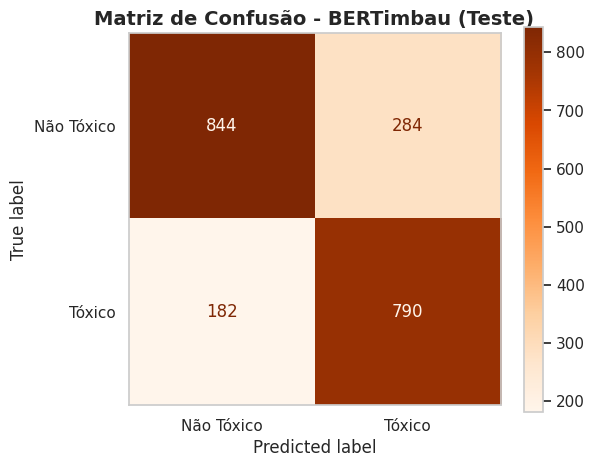

In [7]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Não Tóxico', 'Tóxico'])
disp.plot(cmap='Oranges', ax=ax, values_format='d')

plt.title('Matriz de Confusão - BERTimbau (Teste)', fontsize=14, fontweight='bold')
plt.grid(False)

fig_path = raiz_projeto / 'results' / 'figures' / '03_matriz_confusao_bert.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

## 7. Download dos Resultados e do Modelo
Como não usamos Google Drive, baixamos o modelo treinado e as métricas ao final.

In [ ]:
import shutil
from google.colab import files

# 1. Compactando a pasta de resultados
archive_results = shutil.make_archive("/content/resultados_bert", "zip", str(raiz_projeto / 'results'))
print("Baixando arquivo de resultados...")
files.download(archive_results)

# 2. (Opcional) Compactando apenas o melhor modelo salvo
# O Trainer salva os checkpoints na pasta definida em output_dir
best_model_path = output_dir / "checkpoint-best" # ou o nome que o Trainer gerar
# Se o Trainer não renomeou para checkpoint-best, você pode zipar a pasta inteira output_dir
archive_model = shutil.make_archive("/content/modelo_bertimbau", "zip", str(output_dir))
print("Baixando o modelo treinado (pode demorar)...")
files.download(archive_model)